# Deep Learning-Based Face Segmentation & Recognition System using U-Net

This project focuses on facial feature segmentation and face recognition using deep learning.

## 1. Project Setup

## 2. Importing Libraries

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from tensorflow.keras import layers, models

In [1]:
# @title Default title text
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if 'CelebAMask' in file:
            print(os.path.join(root, file))

/content/drive/MyDrive/Facial_Project/CelebAMask-HQ.zip


In [3]:
import os

zip_path = "/content/drive/MyDrive/Facial_Project/CelebAMask-HQ.zip"

print("Exists:", os.path.exists(zip_path))
print("Size (GB):", os.path.getsize(zip_path)/(1024**3))

Exists: True
Size (GB): 2.937326716259122


In [4]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/Facial_Project/CelebAMask-HQ.zip"
extract_path = "/content/CelebAMask-HQ"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction Complete!")

Extraction Complete!


In [5]:
import os
print(os.listdir("/content/CelebAMask-HQ"))

['CelebAMask-HQ']


In [6]:

import os

print(os.listdir("/content/CelebAMask-HQ/CelebAMask-HQ"))

['README.txt', '.DS_Store', 'CelebAMask-HQ-pose-anno.txt', 'CelebAMask-HQ-attribute-anno.txt', 'CelebAMask-HQ-mask-anno', 'CelebA-HQ-img', 'CelebA-HQ-to-CelebA-mapping.txt']


In [7]:
import os

img_dir = "/content/CelebAMask-HQ/CelebAMask-HQ/CelebA-HQ-img"

print("Total Images:", len(os.listdir(img_dir)))

Total Images: 30000


In [8]:
import os

mask_dir = "/content/CelebAMask-HQ/CelebAMask-HQ/CelebAMask-HQ-mask-anno"

print(os.listdir(mask_dir)[:10])

['10', '.DS_Store', '14', '4', '2', '12', '11', '3', '0', '5']


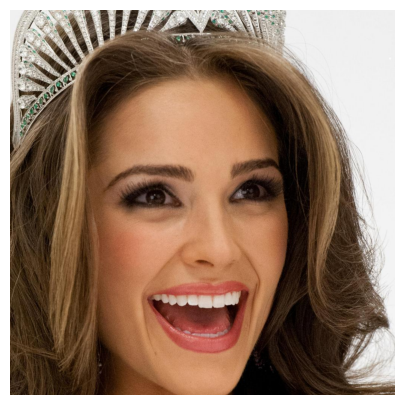

In [9]:
import cv2
import matplotlib.pyplot as plt

img_path = "/content/CelebAMask-HQ/CelebAMask-HQ/CelebA-HQ-img/0.jpg"

img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(5,5))
plt.imshow(img)
plt.axis("off")
plt.show()
#visulally verify image uploaded

In [10]:
import os

mask_folder = "/content/CelebAMask-HQ/CelebAMask-HQ/CelebAMask-HQ-mask-anno/0"

files = sorted(os.listdir(mask_folder))

print("Total files:", len(files))
print(files[:50])

Total files: 24796
['00000_hair.png', '00000_l_brow.png', '00000_l_eye.png', '00000_l_lip.png', '00000_mouth.png', '00000_neck.png', '00000_nose.png', '00000_r_brow.png', '00000_r_eye.png', '00000_skin.png', '00000_u_lip.png', '00001_cloth.png', '00001_hair.png', '00001_l_brow.png', '00001_l_ear.png', '00001_l_eye.png', '00001_l_lip.png', '00001_mouth.png', '00001_neck.png', '00001_nose.png', '00001_r_brow.png', '00001_r_ear.png', '00001_r_eye.png', '00001_skin.png', '00001_u_lip.png', '00002_ear_r.png', '00002_hair.png', '00002_l_brow.png', '00002_l_ear.png', '00002_l_eye.png', '00002_l_lip.png', '00002_neck.png', '00002_nose.png', '00002_r_brow.png', '00002_r_eye.png', '00002_skin.png', '00002_u_lip.png', '00003_hair.png', '00003_l_brow.png', '00003_l_eye.png', '00003_l_lip.png', '00003_mouth.png', '00003_neck.png', '00003_nose.png', '00003_r_brow.png', '00003_r_eye.png', '00003_skin.png', '00003_u_lip.png', '00004_cloth.png', '00004_hair.png']


In [11]:
import cv2

img = cv2.imread("/content/CelebAMask-HQ/CelebAMask-HQ/CelebA-HQ-img/0.jpg")

mask = cv2.imread(
"/content/CelebAMask-HQ/CelebAMask-HQ/CelebAMask-HQ-mask-anno/0/00000_hair.png",
0
)

print("Image Shape:", img.shape)
print("Mask Shape :", mask.shape)

Image Shape: (1024, 1024, 3)
Mask Shape : (512, 512)


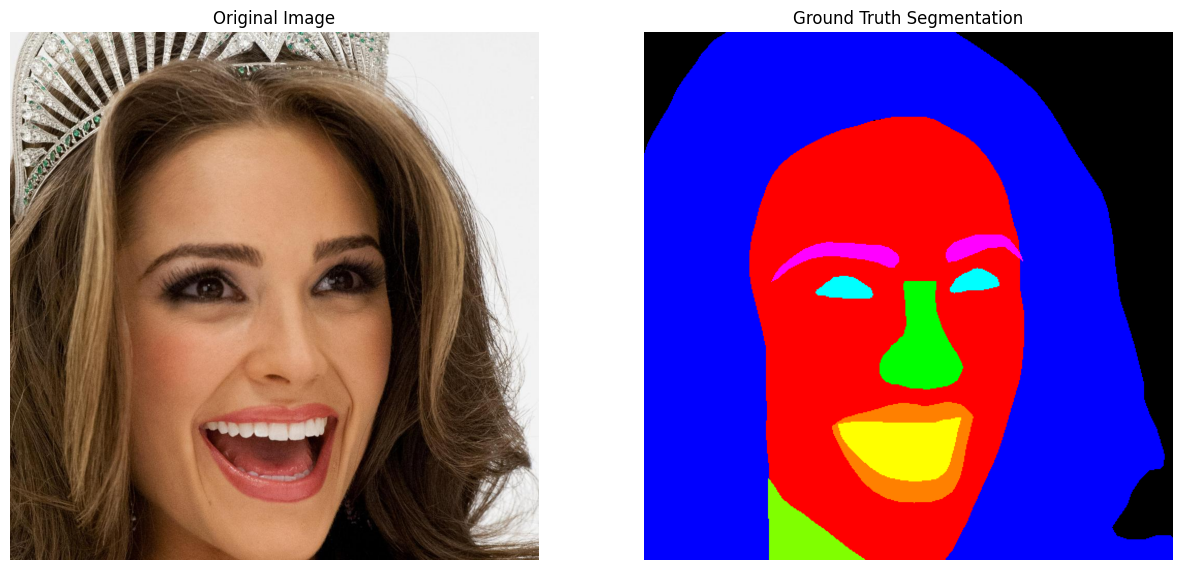

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# ----------------------------
# Load Original Image
# ----------------------------

img_path = "/content/CelebAMask-HQ/CelebAMask-HQ/CelebA-HQ-img/0.jpg"

img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

h, w = img.shape[:2]

# ----------------------------
# Create Empty Color Mask
# ----------------------------

colored_mask = np.zeros((h, w, 3), dtype=np.uint8)

# ----------------------------
# Mask Folder
# ----------------------------

mask_folder = "/content/CelebAMask-HQ/CelebAMask-HQ/CelebAMask-HQ-mask-anno/0"

img_id = "00000"

# ----------------------------
# Define Colors
# ----------------------------

colors = {
    "skin":  [255, 0, 0],
    "hair":  [0, 0, 255],
    "nose":  [0, 255, 0],
    "mouth": [255, 255, 0],
    "l_eye": [0, 255, 255],
    "r_eye": [0, 255, 255],
    "l_brow":[255, 0, 255],
    "r_brow":[255, 0, 255],
    "u_lip": [255, 128, 0],
    "l_lip": [255, 128, 0],
    "neck":  [128, 255, 0]
}

# ----------------------------
# Merge All Masks
# ----------------------------

for part, color in colors.items():

    mask_path = os.path.join(
        mask_folder,
        f"{img_id}_{part}.png"
    )

    if os.path.exists(mask_path):

        mask = cv2.imread(mask_path, 0)

        mask = cv2.resize(
            mask,
            (w, h),
            interpolation=cv2.INTER_NEAREST
        )

        colored_mask[mask > 0] = color

# ----------------------------
# Display Results
# ----------------------------

plt.figure(figsize=(15,7))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(colored_mask)
plt.title("Ground Truth Segmentation")
plt.axis("off")

plt.show()

In [13]:
import os

img_folder = "/content/CelebAMask-HQ/CelebAMask-HQ/CelebA-HQ-img"

images = sorted(os.listdir(img_folder))

print("Total Images:", len(images))
print(images[:10])

Total Images: 30000
['0.jpg', '1.jpg', '10.jpg', '100.jpg', '1000.jpg', '10000.jpg', '10001.jpg', '10002.jpg', '10003.jpg', '10004.jpg']


In [14]:
X = []   # Face Images
Y = []   # Segmentation Masks

In [15]:
import os

mask_root = "/content/CelebAMask-HQ/CelebAMask-HQ/CelebAMask-HQ-mask-anno"

print(sorted(os.listdir(mask_root)))

['.DS_Store', '0', '1', '10', '11', '12', '13', '14', '2', '3', '4', '5', '6', '7', '8', '9']


In [16]:
for i in [0, 1500, 2500, 4500]:
    print(i, "-> Folder", i // 2000)

0 -> Folder 0
1500 -> Folder 0
2500 -> Folder 1
4500 -> Folder 2


In [17]:
X = []
Y = []

print("Dataset initialized")

Dataset initialized


In [18]:
for img_num in range(5):
    print(img_num)

0
1
2
3
4


In [19]:
import cv2
import numpy as np
import os

X = []
Y = []

img_folder = "/content/CelebAMask-HQ/CelebAMask-HQ/CelebA-HQ-img"
mask_root = "/content/CelebAMask-HQ/CelebAMask-HQ/CelebAMask-HQ-mask-anno"

colors = {
    "skin":  [255, 0, 0],
    "hair":  [0, 0, 255],
    "nose":  [0, 255, 0],
    "mouth": [255, 255, 0],
    "l_eye": [0, 255, 255],
    "r_eye": [0, 255, 255],
    "l_brow":[255, 0, 255],
    "r_brow":[255, 0, 255],
    "u_lip": [255, 128, 0],
    "l_lip": [255, 128, 0],
    "neck":  [128, 255, 0]
}

for img_num in range(500):

    img_path = os.path.join(img_folder, f"{img_num}.jpg")
    img = cv2.imread(img_path)

    if img is None:
        continue

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Resize immediately
    img = cv2.resize(img, (256, 256))

    h, w = img.shape[:2]

    folder_num = img_num // 2000
    mask_folder = os.path.join(mask_root, str(folder_num))

    img_id = f"{img_num:05d}"

    colored_mask = np.zeros((h, w, 3), dtype=np.uint8)

    for part, color in colors.items():

        mask_path = os.path.join(
            mask_folder,
            f"{img_id}_{part}.png"
        )

        if os.path.exists(mask_path):

            mask = cv2.imread(mask_path, 0)

            mask = cv2.resize(
                mask,
                (w, h),
                interpolation=cv2.INTER_NEAREST
            )

            colored_mask[mask > 0] = color

    X.append(img)
    Y.append(colored_mask)

print("Images Loaded :", len(X))
print("Masks Loaded  :", len(Y))
print("Dataset Creation Successful!")

Images Loaded : 500
Masks Loaded  : 500
Dataset Creation Successful!


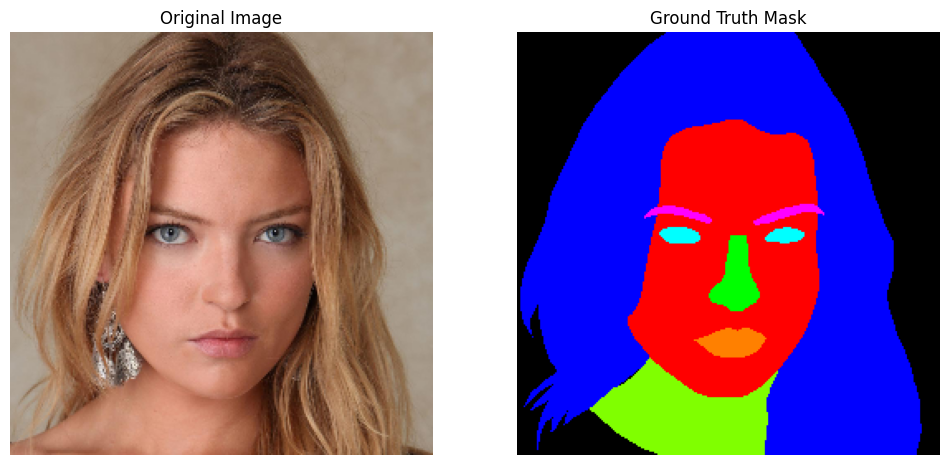

In [20]:
import matplotlib.pyplot as plt

idx = 5

plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.imshow(X[idx])
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(Y[idx])
plt.title("Ground Truth Mask")
plt.axis("off")

plt.show()

In [21]:
import cv2
import numpy as np

X_resized = []
Y_resized = []

for i in range(len(X)):

    img = cv2.resize(X[i], (256,256))
    mask = cv2.resize(
        Y[i],
        (256,256),
        interpolation=cv2.INTER_NEAREST
    )

    X_resized.append(img)
    Y_resized.append(mask)

print("Images:", len(X_resized))
print("Masks :", len(Y_resized))
print("Resize Successful!")

Images: 500
Masks : 500
Resize Successful!


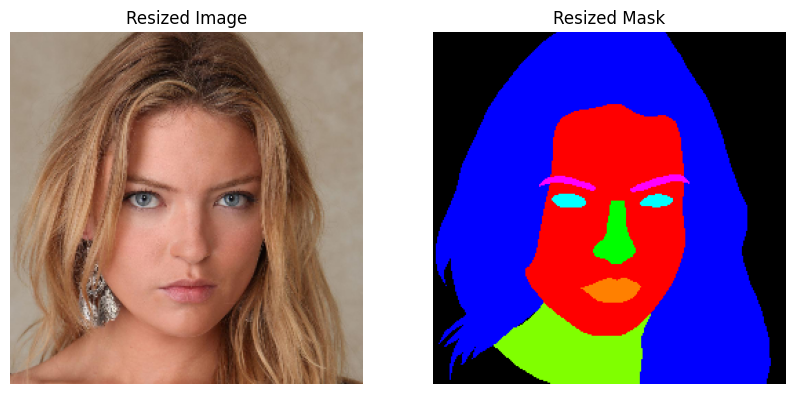

In [22]:
import matplotlib.pyplot as plt

idx = 5

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(X_resized[idx])
plt.title("Resized Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(Y_resized[idx])
plt.title("Resized Mask")
plt.axis("off")

plt.show()

In [23]:
X_resized = np.array(X_resized) / 255.0
Y_resized = np.array(Y_resized) / 255.0

print("X Shape:", X_resized.shape)
print("Y Shape:", Y_resized.shape)

print("Normalization Successful!")

X Shape: (500, 256, 256, 3)
Y Shape: (500, 256, 256, 3)
Normalization Successful!


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X_resized,
    Y_resized,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("Y_train:", Y_train.shape)
print("Y_test :", Y_test.shape)

X_train: (400, 256, 256, 3)
X_test : (100, 256, 256, 3)
Y_train: (400, 256, 256, 3)
Y_test : (100, 256, 256, 3)


In [25]:
import tensorflow as tf
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model

inputs = Input((256, 256, 3))

# Encoder
c1 = Conv2D(16, 3, activation='relu', padding='same')(inputs)
c1 = Conv2D(16, 3, activation='relu', padding='same')(c1)
p1 = MaxPooling2D((2,2))(c1)

c2 = Conv2D(32, 3, activation='relu', padding='same')(p1)
c2 = Conv2D(32, 3, activation='relu', padding='same')(c2)
p2 = MaxPooling2D((2,2))(c2)

# Bottleneck
b1 = Conv2D(64, 3, activation='relu', padding='same')(p2)
b1 = Conv2D(64, 3, activation='relu', padding='same')(b1)

# Decoder
u1 = UpSampling2D((2,2))(b1)
u1 = concatenate([u1, c2])

c3 = Conv2D(32, 3, activation='relu', padding='same')(u1)
c3 = Conv2D(32, 3, activation='relu', padding='same')(c3)

u2 = UpSampling2D((2,2))(c3)
u2 = concatenate([u2, c1])

c4 = Conv2D(16, 3, activation='relu', padding='same')(u2)
c4 = Conv2D(16, 3, activation='relu', padding='same')(c4)

outputs = Conv2D(3, 1, activation='sigmoid')(c4)

model = Model(inputs, outputs)

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      2,320 │ conv2d[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │     36,928 │ conv2d_4[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 128, 128,  │          0 │ conv2d_5[0][0]    │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128, 128,  │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 96)               │            │ conv2d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 128, 128,  │     27,680 │ concatenate[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d_6[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 256, 256,  │          0 │ conv2d_7[0][0]    │
│ (UpSampling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 256, 256,  │          0 │ up_sampling2d_1[… │
│ (Concatenate)       │ 48)               │            │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 256, 256,  │      6,928 │ concatenate_1[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 256, 256,  │      2,320 │ conv2d_8[0][0]  

 Total params: 118,307 (462.14 KB)

 Trainable params: 118,307 (462.14 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
history = model.fit(
    X_train,
    Y_train,
    validation_data=(X_test, Y_test),
    epochs=5,
    batch_size=2
)

Epoch 1/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.5565 - loss: 0.4379 - val_accuracy: 0.5654 - val_loss: 0.3811
Epoch 2/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.5636 - loss: 0.3511 - val_accuracy: 0.6007 - val_loss: 0.3232
Epoch 3/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.5859 - loss: 0.3254 - val_accuracy: 0.5685 - val_loss: 0.3793
Epoch 4/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.5926 - loss: 0.3038 - val_accuracy: 0.5769 - val_loss: 0.3055
Epoch 5/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.6103 - loss: 0.2655 - val_accuracy: 0.6811 - val_loss: 0.2871


In [27]:
print(model)

<Functional name=functional, built=True>


In [28]:
prediction = model.predict(X_test)

print(prediction.shape)

4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 482ms/step
(100, 256, 256, 3)


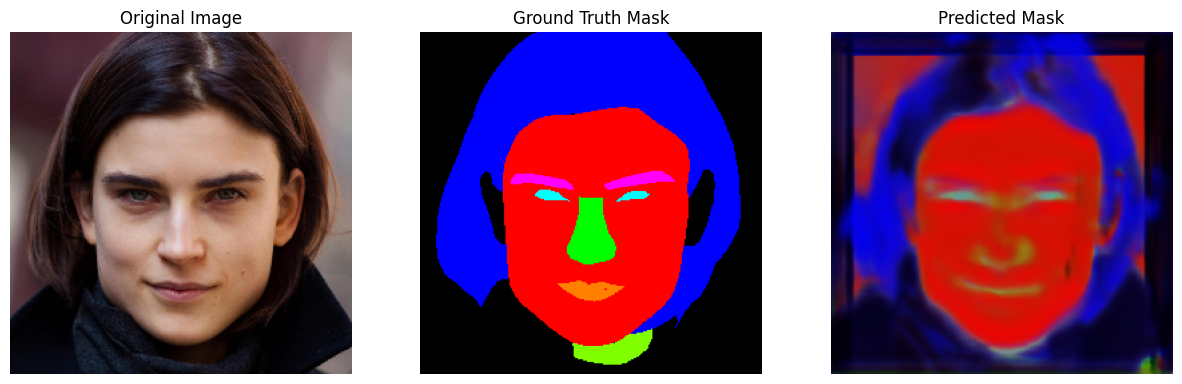

In [29]:
import matplotlib.pyplot as plt

idx = 3

#change idx to see diffrent images

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(X_test[idx])
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(Y_test[idx])
plt.title("Ground Truth Mask")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(prediction[idx])
plt.title("Predicted Mask")
plt.axis("off")

plt.show()

In [30]:
loss, accuracy = model.evaluate(X_test, Y_test)

print("Loss:", loss)
print("Accuracy:", accuracy)

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 370ms/step - accuracy: 0.6811 - loss: 0.2871
Loss: 0.28709620237350464
Accuracy: 0.681140124797821


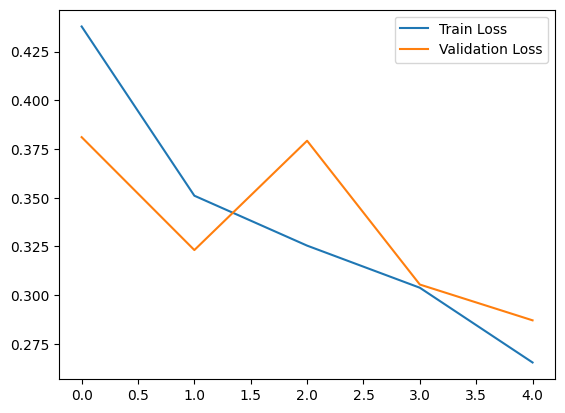

In [31]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.legend(['Train Loss', 'Validation Loss'])
plt.show()

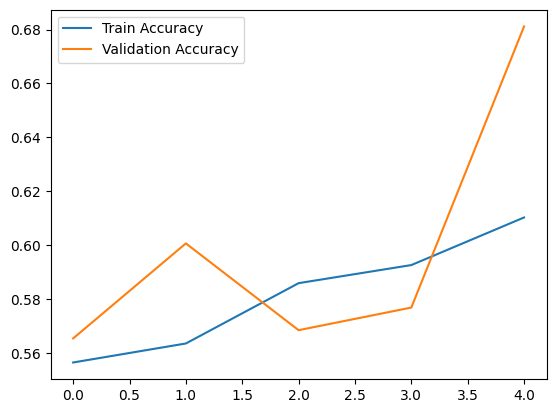

In [32]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.legend(['Train Accuracy', 'Validation Accuracy'])
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
Prediction Shape: (100, 256, 256, 3)


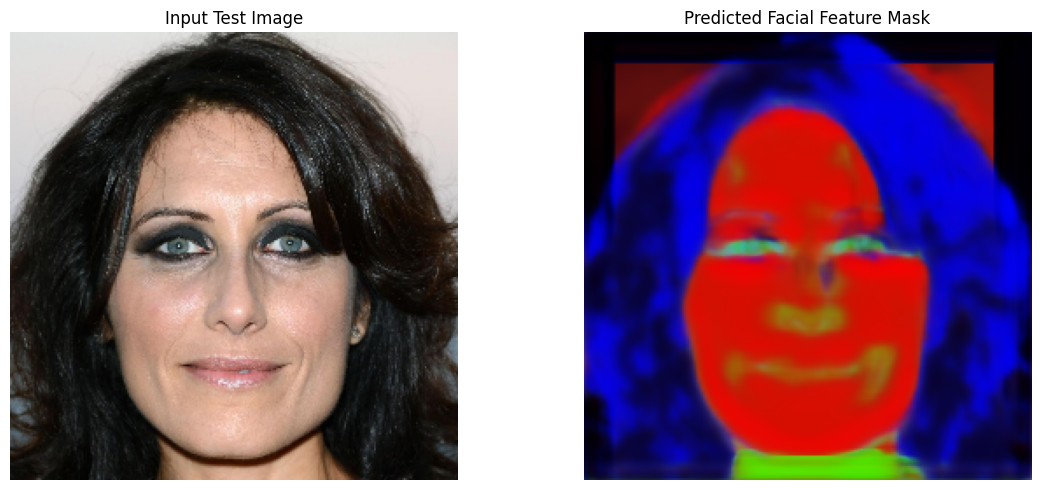

Cell 1 Completed Successfully


In [33]:
# # ============================================================
# CELL 1 - RECOGNITION SETUP
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Generate predictions
prediction = model.predict(X_test, verbose=1)

print("Prediction Shape:", prediction.shape)

# Similarity function
def calculate_mask_similarity(predicted_mask, dataset_mask):

    predicted_binary = (predicted_mask > 0.5).astype(np.float32)
    dataset_binary = (dataset_mask > 0.5).astype(np.float32)

    predicted_flat = predicted_binary.flatten()
    dataset_flat = dataset_binary.flatten()

    denominator = (
        np.linalg.norm(predicted_flat) *
        np.linalg.norm(dataset_flat)
    )

    if denominator == 0:
        return 0.0

    return np.dot(
        predicted_flat,
        dataset_flat
    ) / denominator


# Find best matching image
def find_best_matching_image(predicted_mask, dataset_masks):

    best_index = -1
    best_score = -1

    for i in range(len(dataset_masks)):

        score = calculate_mask_similarity(
            predicted_mask,
            dataset_masks[i]
        )

        if score > best_score:
            best_score = score
            best_index = i

    return best_index, best_score


# Select test image
test_index = 6

test_image = X_test[test_index]
predicted_mask = prediction[test_index]

# Display Input + Predicted Mask
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(test_image)
plt.title("Input Test Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(predicted_mask)
plt.title("Predicted Facial Feature Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Cell 1 Completed Successfully")

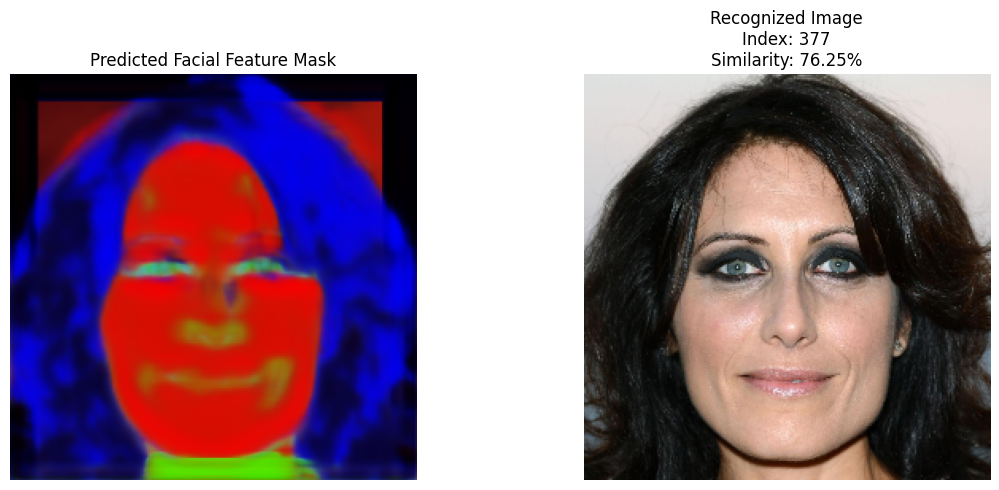

IMAGE RECOGNITION RESULT
Input Test Index : 6
Matched Dataset  : 377
Similarity Score : 76.25 %


In [34]:
# ============================================================
# CELL 2 - RECOGNITION RESULT
# ============================================================

best_index, best_score = find_best_matching_image(
    predicted_mask,
    Y_resized
)

matched_image = X_resized[best_index]

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(predicted_mask)
plt.title("Predicted Facial Feature Mask")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(matched_image)
plt.title(
    f"Recognized Image\n"
    f"Index: {best_index}\n"
    f"Similarity: {best_score*100:.2f}%"
)
plt.axis("off")

plt.tight_layout()
plt.show()

print("================================")
print("IMAGE RECOGNITION RESULT")
print("================================")
print("Input Test Index :", test_index)
print("Matched Dataset  :", best_index)
print("Similarity Score :", round(best_score*100,2), "%")
print("================================")

In [35]:
# ============================================================
# CELL 34 - LOAD OWN FACE DATASET
# ============================================================

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Correct Google Drive path
own_dataset_path = "/content/drive/MyDrive/Facial_Project"

# Person folders
aditi_path = os.path.join(own_dataset_path, "Aditi(Image)")
tanya_path = os.path.join(own_dataset_path, "Tanya(Image)")


# ------------------------------------------------------------
# Function to load images
# ------------------------------------------------------------

def load_images_from_folder(folder_path, person_name):

    images = []
    labels = []
    filenames = []

    for file in os.listdir(folder_path):

        if file.lower().endswith((".jpg", ".jpeg", ".png")):

            image_path = os.path.join(folder_path, file)

            image = cv2.imread(image_path)

            if image is None:
                continue

            # Convert BGR → RGB
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            images.append(image)
            labels.append(person_name)
            filenames.append(file)

    return images, labels, filenames


# ------------------------------------------------------------
# Load Aditi images
# ------------------------------------------------------------

aditi_images, aditi_labels, aditi_files = load_images_from_folder(
    aditi_path,
    "Aditi"
)


# ------------------------------------------------------------
# Load Tanya images
# ------------------------------------------------------------

tanya_images, tanya_labels, tanya_files = load_images_from_folder(
    tanya_path,
    "Tanya"
)


# ------------------------------------------------------------
# Combine both people
# ------------------------------------------------------------

own_images = aditi_images + tanya_images
own_labels = aditi_labels + tanya_labels
own_files = aditi_files + tanya_files


print("================================")
print("OWN FACE DATASET")
print("================================")
print("Aditi images :", len(aditi_images))
print("Tanya images :", len(tanya_images))
print("Total images :", len(own_images))
print("================================")

OWN FACE DATASET
Aditi images : 6
Tanya images : 6
Total images : 12


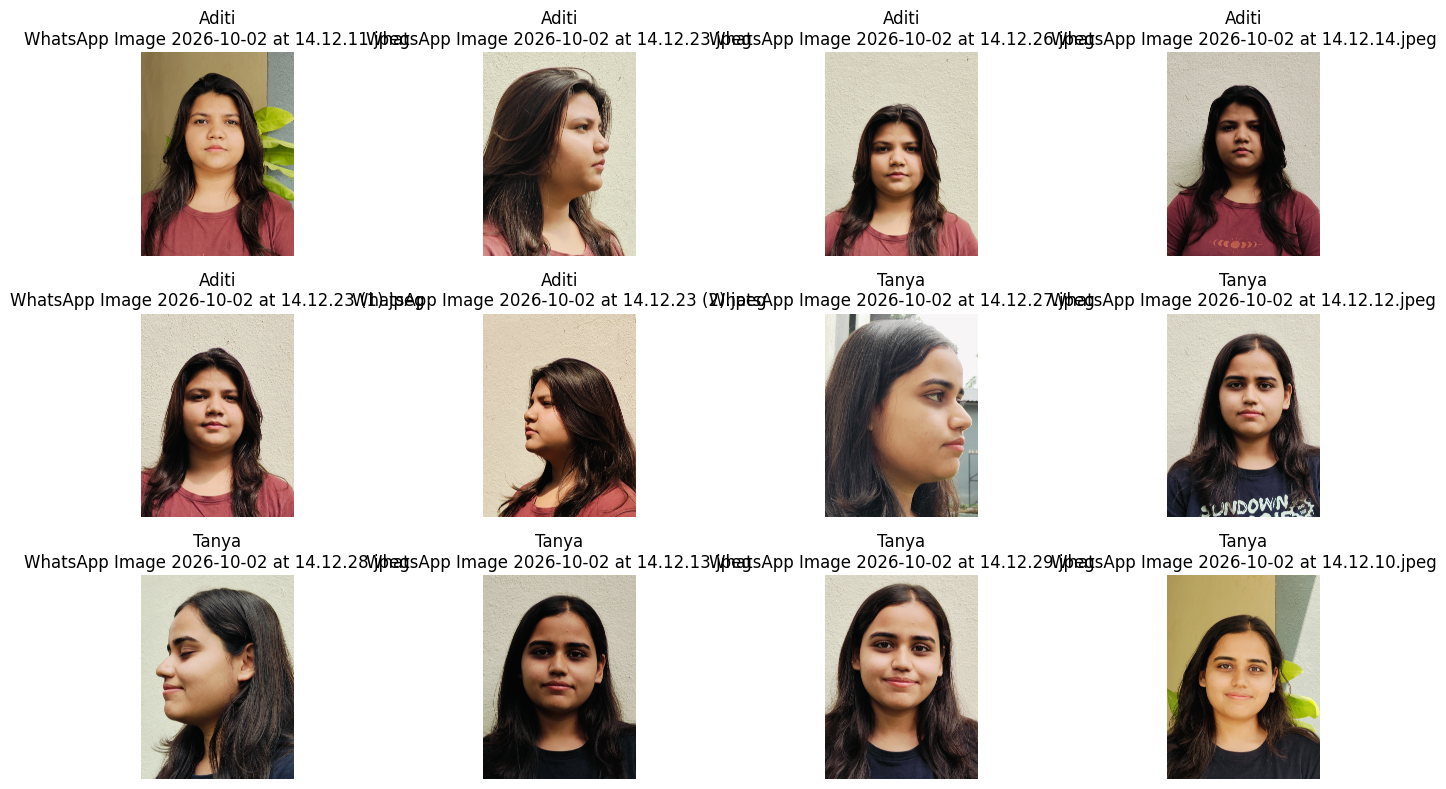

In [36]:
# ============================================================
# CELL 35 - VISUALIZE OWN FACE IMAGES
# ============================================================

plt.figure(figsize=(15, 8))

num_images = min(12, len(own_images))

for i in range(num_images):

    plt.subplot(3, 4, i + 1)

    plt.imshow(own_images[i])

    plt.title(f"{own_labels[i]}\n{own_files[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [37]:
# ============================================================
# CELL 36 - PREPROCESS OWN FACE IMAGES
# ============================================================

own_images_resized = []

for image in own_images:

    # Resize to the U-Net input size
    image_resized = cv2.resize(
        image,
        (256, 256)
    )

    # Normalize pixel values from 0-255 to 0-1
    image_normalized = image_resized / 255.0

    own_images_resized.append(image_normalized)


# Convert list to NumPy array
own_images_resized = np.array(own_images_resized)


print("================================")
print("PREPROCESSING COMPLETE")
print("================================")
print("Original images :", len(own_images))
print("Processed shape :", own_images_resized.shape)
print("Minimum value   :", own_images_resized.min())
print("Maximum value   :", own_images_resized.max())
print("================================")

PREPROCESSING COMPLETE
Original images : 12
Processed shape : (12, 256, 256, 3)
Minimum value   : 0.0
Maximum value   : 0.9882352941176471


In [38]:
# ============================================================
# CELL 37 - PREDICT ON ADITI + TANYA IMAGES
# ============================================================

print("Running U-Net prediction on Aditi and Tanya images...")

own_predictions = model.predict(
    own_images_resized,
    verbose=1
)

print("\n================================")
print("SEGMENTATION COMPLETE")
print("================================")
print("Input shape      :", own_images_resized.shape)
print("Prediction shape :", own_predictions.shape)
print("================================")

Running U-Net prediction on Aditi and Tanya images...
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step

SEGMENTATION COMPLETE
Input shape      : (12, 256, 256, 3)
Prediction shape : (12, 256, 256, 3)


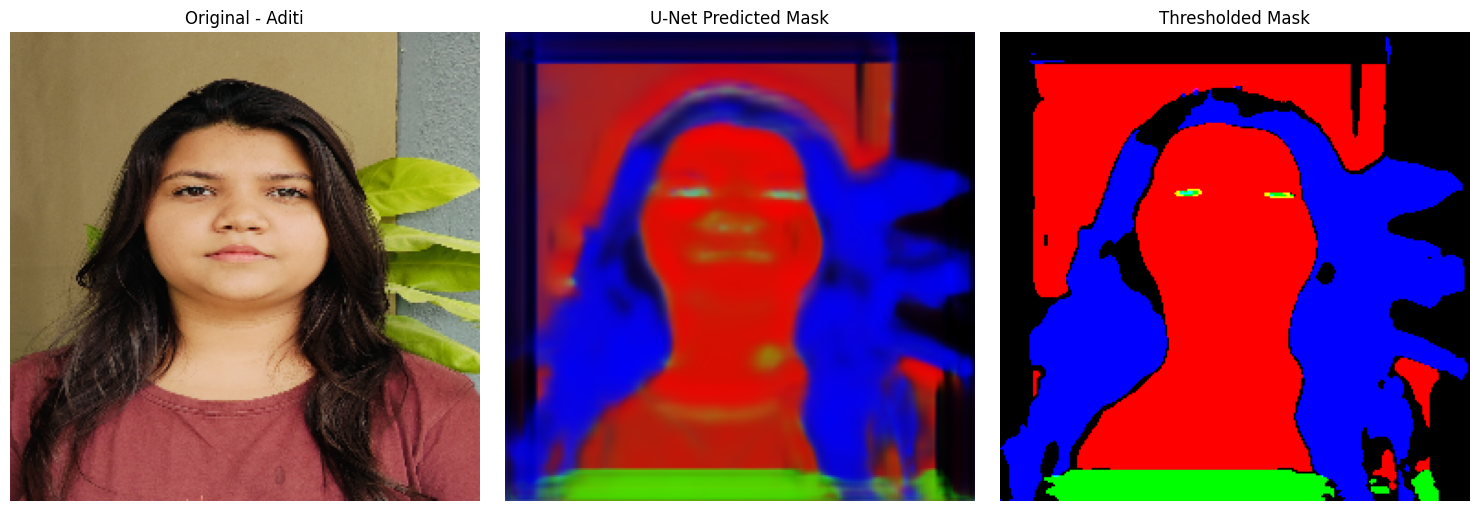

In [39]:
# ============================================================
# CELL 38 - VISUALIZE U-NET PREDICTION
# ============================================================

idx = 0

plt.figure(figsize=(15, 5))

# Original face
plt.subplot(1, 3, 1)
plt.imshow(own_images_resized[idx])
plt.title(f"Original - {own_labels[idx]}")
plt.axis("off")

# U-Net prediction
plt.subplot(1, 3, 2)
plt.imshow(own_predictions[idx])
plt.title("U-Net Predicted Mask")
plt.axis("off")

# Thresholded prediction
plt.subplot(1, 3, 3)
plt.imshow(
    (own_predictions[idx] > 0.5).astype(float)
)
plt.title("Thresholded Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [40]:
# ============================================================
# CELL 39 - CONVERT RGB MASKS TO CLASS LABELS
# ============================================================

import numpy as np

# Number of classes
# 0 = Background
# 1 = Skin
# 2 = Hair
# 3 = Nose
# 4 = Mouth
# 5 = Eyes
# 6 = Eyebrows
# 7 = Lips
# 8 = Neck

NUM_CLASSES = 9

# RGB colors used in your original mask creation
CLASS_COLORS = {
    1: [255, 0, 0],       # Skin
    2: [0, 0, 255],       # Hair
    3: [0, 255, 0],       # Nose
    4: [255, 255, 0],     # Mouth
    5: [0, 255, 255],     # Eyes
    6: [255, 0, 255],     # Eyebrows
    7: [255, 128, 0],     # Lips
    8: [128, 255, 0]      # Neck
}

# Create class mask
Y_class = np.zeros(
    (len(Y_resized), 256, 256),
    dtype=np.uint8
)

for class_id, color in CLASS_COLORS.items():

    color = np.array(color)

    matches = np.all(
        Y_resized * 255 == color,
        axis=-1
    )

    Y_class[matches] = class_id


print("================================")
print("CLASS MASK CREATION")
print("================================")
print("Y_class shape:", Y_class.shape)
print("Classes found:", np.unique(Y_class))
print("================================")

CLASS MASK CREATION
Y_class shape: (500, 256, 256)
Classes found: [0 1 2 3 4 5 6 7 8]


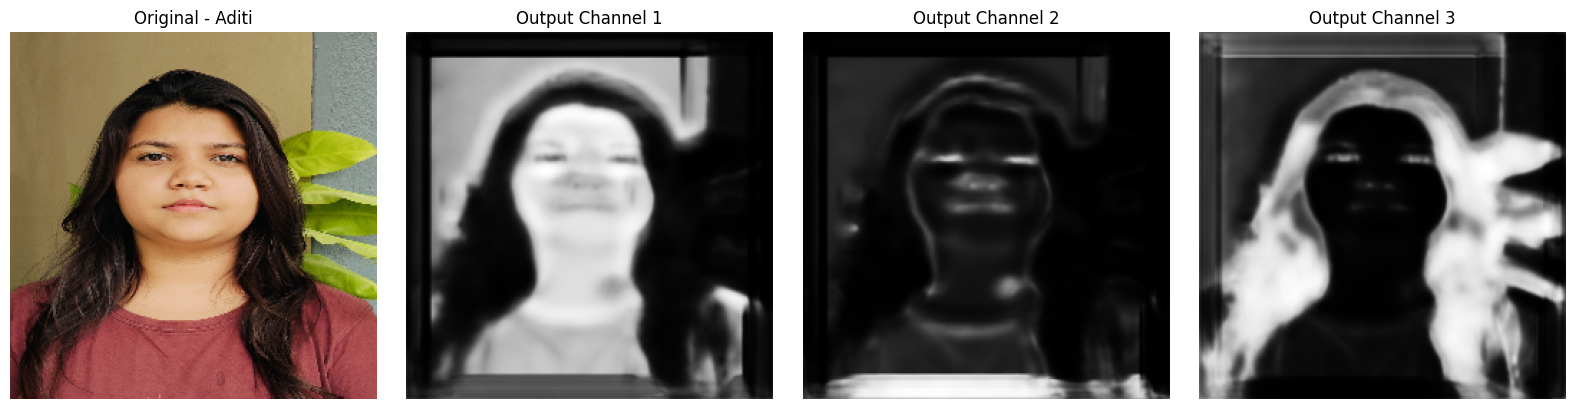

In [41]:
# ============================================================
# CELL 37 - VISUALIZE U-NET OUTPUT CHANNELS
# ============================================================

idx = 0   # Aditi image

plt.figure(figsize=(16, 4))

# Original image
plt.subplot(1, 4, 1)
plt.imshow(own_images_resized[idx])
plt.title("Original - Aditi")
plt.axis("off")

# Channel 1
plt.subplot(1, 4, 2)
plt.imshow(own_predictions[idx, :, :, 0], cmap="gray")
plt.title("Output Channel 1")
plt.axis("off")

# Channel 2
plt.subplot(1, 4, 3)
plt.imshow(own_predictions[idx, :, :, 1], cmap="gray")
plt.title("Output Channel 2")
plt.axis("off")

# Channel 3
plt.subplot(1, 4, 4)
plt.imshow(own_predictions[idx, :, :, 2], cmap="gray")
plt.title("Output Channel 3")
plt.axis("off")

plt.tight_layout()
plt.show()

In [42]:
# ============================================================
# CELL 55 - LOAD ORIGINAL FACE IMAGES
# ============================================================

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

base_path = "/content/drive/MyDrive/Facial_Project"

aditi_path = os.path.join(base_path, "Aditi(Image)")
tanya_path = os.path.join(base_path, "Tanya(Image)")


def load_person_images(folder_path, person_name):

    images = []
    names = []

    for file in sorted(os.listdir(folder_path)):

        if file.lower().endswith((".jpg", ".jpeg", ".png")):

            path = os.path.join(folder_path, file)

            image = cv2.imread(path)

            if image is None:
                continue

            image = cv2.cvtColor(
                image,
                cv2.COLOR_BGR2RGB
            )

            images.append(image)
            names.append(file)

    print(person_name, "images loaded:", len(images))

    return images, names


aditi_images, aditi_files = load_person_images(
    aditi_path,
    "Aditi"
)

tanya_images, tanya_files = load_person_images(
    tanya_path,
    "Tanya"
)

print("Total Aditi:", len(aditi_images))
print("Total Tanya:", len(tanya_images))

Aditi images loaded: 6
Tanya images loaded: 6
Total Aditi: 6
Total Tanya: 6


In [43]:
# ============================================================
# CELL 56 - PREPROCESS ADITI AND TANYA IMAGES
# ============================================================

all_own_images = aditi_images + tanya_images
all_own_labels = (
    ["Aditi"] * len(aditi_images)
    + ["Tanya"] * len(tanya_images)
)

all_own_files = aditi_files + tanya_files

X_own = []

for image in all_own_images:

    # Same size as original dataset
    image = cv2.resize(
        image,
        (256, 256)
    )

    # Same normalization as original dataset
    image = image.astype(np.float32) / 255.0

    X_own.append(image)

X_own = np.array(X_own)

print("Own images shape:", X_own.shape)
print("Min value:", X_own.min())
print("Max value:", X_own.max())

Own images shape: (12, 256, 256, 3)
Min value: 0.0
Max value: 0.9882353


In [44]:
# ============================================================
# CELL 57 - PREDICT USING ORIGINAL U-NET
# ============================================================

own_prediction = model.predict(
    X_own,
    verbose=1
)

print("Prediction shape:", own_prediction.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
Prediction shape: (12, 256, 256, 3)


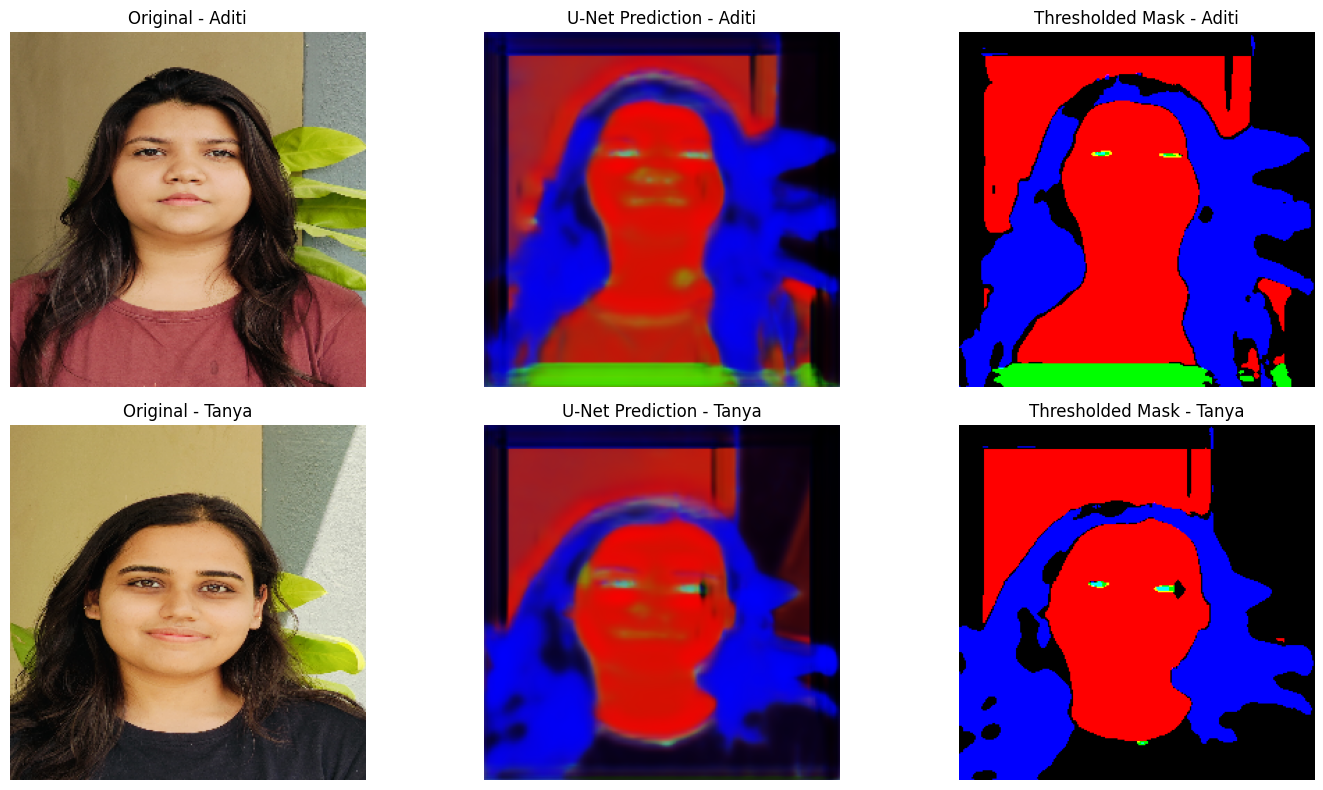

In [45]:
# ============================================================
# CELL 58 - VISUALIZE ORIGINAL U-NET PREDICTIONS
# ============================================================

# Aditi = first image
# Tanya = seventh image

indices = [0, 6]
names = ["Aditi", "Tanya"]

plt.figure(figsize=(15, 8))

for row, (idx, name) in enumerate(zip(indices, names)):

    # Original
    plt.subplot(2, 3, row * 3 + 1)
    plt.imshow(X_own[idx])
    plt.title(f"Original - {name}")
    plt.axis("off")

    # Ground-truth style output from U-Net
    plt.subplot(2, 3, row * 3 + 2)
    plt.imshow(own_prediction[idx])
    plt.title(f"U-Net Prediction - {name}")
    plt.axis("off")

    # Thresholded output
    plt.subplot(2, 3, row * 3 + 3)
    plt.imshow(
        (own_prediction[idx] > 0.5).astype(float)
    )
    plt.title(f"Thresholded Mask - {name}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [46]:
# ============================================================
# CELL 59 - PREPARE MASKS FOR MATCHING
# ============================================================

# Convert U-Net probability output into binary masks
own_binary_masks = (own_prediction >= 0.5).astype(np.float32)

print("Binary mask shape:", own_binary_masks.shape)

# Separate the two people
aditi_masks = own_binary_masks[:6]
tanya_masks = own_binary_masks[6:12]

print("Aditi masks :", aditi_masks.shape)
print("Tanya masks :", tanya_masks.shape)

Binary mask shape: (12, 256, 256, 3)
Aditi masks : (6, 256, 256, 3)
Tanya masks : (6, 256, 256, 3)


In [47]:
# ============================================================
# CELL 60 - FIND BEST MATCHING OWN IMAGE
# ============================================================

def find_best_matching_own_image(
    predicted_mask,
    reference_masks,
    reference_images,
    reference_labels,
    reference_files
):

    best_score = -1
    best_index = -1

    for i in range(len(reference_masks)):

        score = mask_similarity(
            predicted_mask,
            reference_masks[i]
        )

        if score > best_score:
            best_score = score
            best_index = i

    return (
        best_index,
        best_score,
        reference_images[best_index],
        reference_labels[best_index],
        reference_files[best_index]
    )

In [48]:
# ============================================================
# CELL 61 - CREATE REFERENCE DATABASE
# ============================================================

reference_masks = np.concatenate(
    [aditi_masks, tanya_masks],
    axis=0
)

reference_images = (
    aditi_images + tanya_images
)

reference_labels = (
    ["Aditi"] * len(aditi_images)
    +
    ["Tanya"] * len(tanya_images)
)

reference_files = (
    aditi_files + tanya_files
)

print("Reference masks :", reference_masks.shape)
print("Reference images:", len(reference_images))
print("Reference labels:", reference_labels)

Reference masks : (12, 256, 256, 3)
Reference images: 12
Reference labels: ['Aditi', 'Aditi', 'Aditi', 'Aditi', 'Aditi', 'Aditi', 'Tanya', 'Tanya', 'Tanya', 'Tanya', 'Tanya', 'Tanya']


In [49]:
# ============================================================
# CELL 62 - SELECT TEST IMAGE
# ============================================================

test_index = 11

test_image = X_own[test_index]
test_mask = own_binary_masks[test_index]

test_person = all_own_labels[test_index]
test_file = all_own_files[test_index]

print("Test person :", test_person)
print("Test image  :", test_file)

Test person : Tanya
Test image  : WhatsApp Image 2026-10-02 at 14.12.29.jpeg


In [50]:
# ============================================================
# CELL 63 - REMOVE TEST IMAGE FROM REFERENCE SET
# ============================================================

reference_indices = [
    i for i in range(len(reference_images))
    if i != test_index
]

test_reference_masks = reference_masks[
    reference_indices
]

test_reference_images = [
    reference_images[i]
    for i in reference_indices
]

test_reference_labels = [
    reference_labels[i]
    for i in reference_indices
]

test_reference_files = [
    reference_files[i]
    for i in reference_indices
]

print(
    "Reference images available:",
    len(test_reference_images)
)

Reference images available: 11


IMAGE RECOGNITION RESULT
Test Image      : WhatsApp Image 2026-10-02 at 14.12.29.jpeg
Actual Person   : Tanya
Recognized Image: WhatsApp Image 2026-10-02 at 14.12.10.jpeg
Recognized As   : Tanya
Similarity Score: 47.5 %


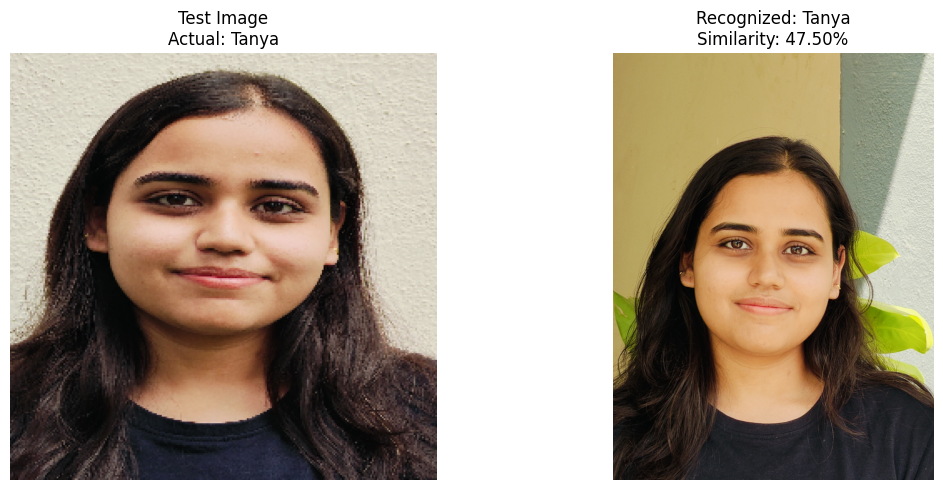

In [51]:

# ============================================================
# CELL 64 - COMPLETE FACE RECOGNITION + VISUALIZATION
# ============================================================

import numpy as np
import cv2
import matplotlib.pyplot as plt

# STEP 1: Calculate mask similarity
def mask_similarity(predicted_mask, reference_mask):
    predicted_mask = np.asarray(predicted_mask)
    reference_mask = np.asarray(reference_mask)

    if predicted_mask.shape[:2] != reference_mask.shape[:2]:
        reference_mask = cv2.resize(
            reference_mask,
            (predicted_mask.shape[1], predicted_mask.shape[0]),
            interpolation=cv2.INTER_NEAREST
        )

    predicted_binary = predicted_mask > 0
    reference_binary = reference_mask > 0

    intersection = np.logical_and(
        predicted_binary, reference_binary
    ).sum()

    union = np.logical_or(
        predicted_binary, reference_binary
    ).sum()

    return intersection / union if union > 0 else 1.0


# STEP 2: Find best matching image
def find_best_matching_own_image(
    predicted_mask,
    reference_masks,
    reference_images,
    reference_labels,
    reference_files
):
    if len(reference_masks) == 0:
        raise ValueError("No reference masks available.")

    scores = [
        mask_similarity(predicted_mask, ref_mask)
        for ref_mask in reference_masks
    ]

    best_index = int(np.argmax(scores))

    return (
        best_index,
        float(scores[best_index]),
        reference_images[best_index],
        reference_labels[best_index],
        reference_files[best_index]
    )


# STEP 3: Perform recognition
best_index, best_score, recognized_image, recognized_person, recognized_file = \
    find_best_matching_own_image(
        test_mask,
        test_reference_masks,
        test_reference_images,
        test_reference_labels,
        test_reference_files
    )


# STEP 4: Print results
print("======================================")
print("IMAGE RECOGNITION RESULT")
print("======================================")
print("Test Image      :", test_file)
print("Actual Person   :", test_person)
print("Recognized Image:", recognized_file)
print("Recognized As   :", recognized_person)
print("Similarity Score:", round(best_score * 100, 2), "%")
print("======================================")


# STEP 5: Display images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(test_image)
plt.title(f"Test Image\nActual: {test_person}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(recognized_image)
plt.title(
    f"Recognized: {recognized_person}\n"
    f"Similarity: {best_score * 100:.2f}%"
)
plt.axis("off")

plt.tight_layout()
plt.show()


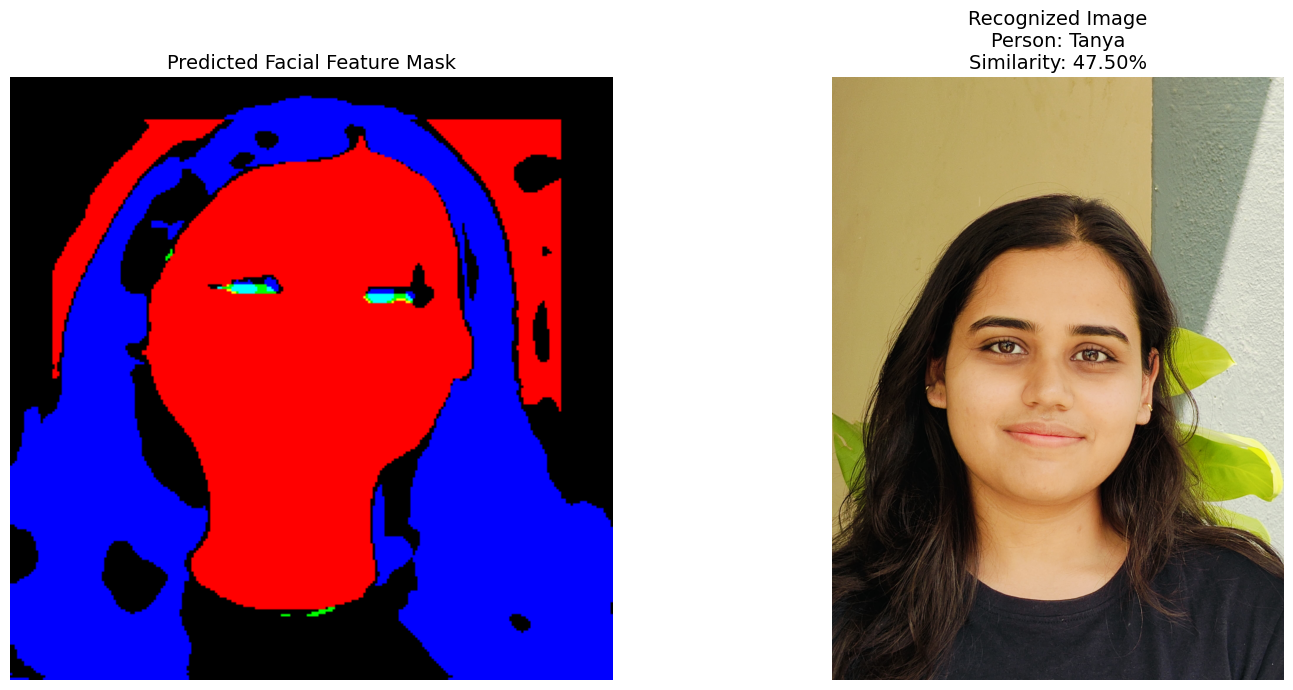

In [52]:
# ============================================================
# CELL 65 - DISPLAY RECOGNITION RESULT
# ============================================================

plt.figure(figsize=(16, 7))

# ------------------------------------------------------------
# Left: Predicted Facial Feature Mask
# ------------------------------------------------------------

plt.subplot(1, 2, 1)

plt.imshow(test_mask)

plt.title(
    "Predicted Facial Feature Mask",
    fontsize=14
)

plt.axis("off")


# ------------------------------------------------------------
# Right: Recognized Image
# ------------------------------------------------------------

plt.subplot(1, 2, 2)

plt.imshow(recognized_image)

plt.title(
    f"Recognized Image\n"
    f"Person: {recognized_person}\n"
    f"Similarity: {best_score * 100:.2f}%",
    fontsize=14
)

plt.axis("off")


plt.tight_layout()
plt.show()